In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from pathlib import Path
import pandas as pd

data_path = Path(
    r"D:\Yuva Intern Tasks\Task 2\Dataset\online+retail\Online Retail.xlsx"
)

df = pd.read_excel(data_path)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print("Missing values:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Column names:")
print(df.columns.tolist())

Missing values:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268
Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [4]:
import pandas as pd
from scipy import stats

# Date and revenue columns prepare karo
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

# Valid sales rows select karo
sales = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (df["InvoiceDate"].notna())
].copy()

# January aur February 2011 ka daily revenue calculate karo
sales["Date"] = sales["InvoiceDate"].dt.date
sales["Month"] = sales["InvoiceDate"].dt.to_period("M").astype(str)

daily_revenue = (
    sales.groupby(["Month", "Date"])["Revenue"]
    .sum()
    .reset_index()
)

jan = daily_revenue.loc[
    daily_revenue["Month"] == "2011-01", "Revenue"
]

feb = daily_revenue.loc[
    daily_revenue["Month"] == "2011-02", "Revenue"
]

print("January daily observations:", len(jan))
print("February daily observations:", len(feb))
print("January average daily revenue:", round(jan.mean(), 2))
print("February average daily revenue:", round(feb.mean(), 2))

# Welch's independent two-sample t-test
if len(jan) >= 2 and len(feb) >= 2:
    result = stats.ttest_ind(jan, feb, equal_var=False)

    print("\nT-statistic:", round(result.statistic, 4))
    print("P-value:", round(result.pvalue, 6))

    alpha = 0.05

    if result.pvalue < alpha:
        print("Decision: Reject the null hypothesis.")
    else:
        print("Decision: Fail to reject the null hypothesis.")
else:
    print("Not enough observations to perform the test.")

January daily observations: 24
February daily observations: 24
January average daily revenue: 28806.86
February average daily revenue: 21818.0

T-statistic: 1.6061
P-value: 0.117977
Decision: Fail to reject the null hypothesis.


In [5]:
import numpy as np
from scipy import stats

# Difference between average daily revenue
mean_diff = jan.mean() - feb.mean()

# Welch's t-test
result = stats.ttest_ind(jan, feb, equal_var=False)

# 95% confidence interval for mean difference
n1, n2 = len(jan), len(feb)
v1, v2 = jan.var(ddof=1), feb.var(ddof=1)

se = np.sqrt(v1 / n1 + v2 / n2)

df_welch = (v1 / n1 + v2 / n2) ** 2 / (
    (v1 / n1) ** 2 / (n1 - 1) +
    (v2 / n2) ** 2 / (n2 - 1)
)

critical_t = stats.t.ppf(0.975, df_welch)

ci_lower = mean_diff - critical_t * se
ci_upper = mean_diff + critical_t * se

# Cohen's d (pooled standard deviation)
pooled_sd = np.sqrt(
    ((n1 - 1) * v1 + (n2 - 1) * v2) /
    (n1 + n2 - 2)
)

cohens_d = mean_diff / pooled_sd if pooled_sd != 0 else np.nan

print("Mean difference (January - February):", round(mean_diff, 2))
print("95% Confidence Interval:", (round(ci_lower, 2), round(ci_upper, 2)))
print("Cohen's d:", round(cohens_d, 3))
print("P-value:", round(result.pvalue, 6))

Mean difference (January - February): 6988.86
95% Confidence Interval: (np.float64(-1871.31), np.float64(15849.03))
Cohen's d: 0.464
P-value: 0.117977


In [6]:
from scipy import stats
import pandas as pd
import numpy as np

# Valid sales records select karo
sales_corr = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (df["InvoiceDate"].notna())
].copy()

# Revenue calculate karo
sales_corr["Revenue"] = (
    sales_corr["Quantity"] * sales_corr["UnitPrice"]
)

# Pearson correlation test
correlation, p_value = stats.pearsonr(
    sales_corr["Quantity"],
    sales_corr["Revenue"]
)

print("Pearson correlation:", round(correlation, 4))
print("P-value:", f"{p_value:.6g}")

if p_value < 0.05:
    print("Decision: Reject the null hypothesis.")
    print("There is evidence of a linear correlation.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("Insufficient evidence of a linear correlation.")

Pearson correlation: 0.9073
P-value: 0
Decision: Reject the null hypothesis.
There is evidence of a linear correlation.


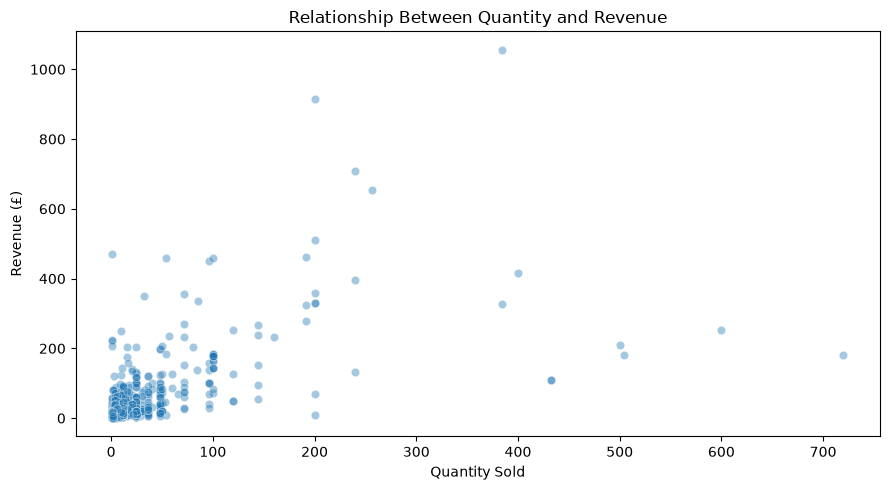

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sample = sales_corr.sample(
    n=min(3000, len(sales_corr)),
    random_state=42
)

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=sample,
    x="Quantity",
    y="Revenue",
    alpha=0.4
)

plt.title("Relationship Between Quantity and Revenue")
plt.xlabel("Quantity Sold")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.show()

In [8]:
import pandas as pd
from scipy.stats import chi2_contingency

# Original dataset se required columns select karo
chi_df = df[
    df["InvoiceDate"].notna() &
    df["InvoiceNo"].notna()
].copy()

# Month create karo
chi_df["Month"] = chi_df["InvoiceDate"].dt.strftime("%Y-%m")

# Cancellations: InvoiceNo 'C' se start hota hai
chi_df["TransactionType"] = chi_df["InvoiceNo"].astype(str).str.startswith("C")
chi_df["TransactionType"] = chi_df["TransactionType"].map({
    True: "Cancellation",
    False: "Regular"
})

# Contingency table
contingency_table = pd.crosstab(
    chi_df["Month"],
    chi_df["TransactionType"]
)

display(contingency_table)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("P-value:", f"{p_value:.6g}")

if p_value < 0.05:
    print("Decision: Reject the null hypothesis.")
    print("There is evidence of an association between month and transaction type.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("Insufficient evidence of an association.")

TransactionType,Cancellation,Regular
Month,,
2010-12,728,41753
2011-01,701,34446
2011-02,475,27232
2011-03,699,36049
2011-04,559,29357
2011-05,621,36409
2011-06,711,36163
2011-07,685,38833
2011-08,668,34616


Chi-square statistic: 186.9072
Degrees of freedom: 12
P-value: 1.62567e-33
Decision: Reject the null hypothesis.
There is evidence of an association between month and transaction type.


In [9]:
print("Minimum expected frequency:", round(expected.min(), 2))
print(
    "Expected cells below 5 (%):",
    round((expected < 5).mean() * 100, 2)
)

Minimum expected frequency: 437.48
Expected cells below 5 (%): 0.0


In [10]:
import pandas as pd
import statsmodels.api as sm

# Valid sales records
reg_df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (df["InvoiceDate"].notna())
].copy()

reg_df["Revenue"] = reg_df["Quantity"] * reg_df["UnitPrice"]

# Bahut bade dataset ko manageable sample mein lena
reg_sample = reg_df.sample(
    n=min(20000, len(reg_df)),
    random_state=42
)

# Independent variables
X = reg_sample[["Quantity", "UnitPrice"]]

# Constant/intercept add karo
X = sm.add_constant(X)

# Dependent variable
y = reg_sample["Revenue"]

# Regression model fit karo
model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                Revenue   R-squared:                       0.284
Model:                            OLS   Adj. R-squared:                  0.284
Method:                 Least Squares   F-statistic:                     3975.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:29:18   Log-Likelihood:            -1.3839e+05
No. Observations:               20000   AIC:                         2.768e+05
Df Residuals:                   19997   BIC:                         2.768e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -48.6255      1.908    -25.483      0.0

In [11]:
from pathlib import Path

output_dir = Path(r"D:\Yuva Intern Tasks\Task 4\Output")
output_dir.mkdir(parents=True, exist_ok=True)

results = pd.DataFrame({
    "Metric": [
        "R-squared",
        "Adjusted R-squared",
        "F-statistic",
        "Model p-value"
    ],
    "Value": [
        model.rsquared,
        model.rsquared_adj,
        model.fvalue,
        model.f_pvalue
    ]
})

results.to_csv(
    output_dir / "Week4_Regression_Results.csv",
    index=False
)

print("Regression results saved successfully!")
display(results)

Regression results saved successfully!


,Metric,Value
0,R-squared,0.284452
1,Adjusted R-squared,0.284380
2,F-statistic,3974.706173
3,Model p-value,0.000000


In [12]:
from pathlib import Path
import pandas as pd

output_dir = Path(r"D:\Yuva Intern Tasks\Task 4\Output")
output_dir.mkdir(parents=True, exist_ok=True)

# Results ko ek table mein arrange karo
summary = pd.DataFrame([
    {
        "Test": "Welch's t-test",
        "Research Question": "January vs February average daily revenue",
        "Statistic": result.statistic,
        "P_Value": result.pvalue,
        "Significance_Level": 0.05
    },
    {
        "Test": "Pearson Correlation",
        "Research Question": "Quantity vs Revenue",
        "Statistic": correlation,
        "P_Value": p_value,
        "Significance_Level": 0.05
    },
    {
        "Test": "Chi-square",
        "Research Question": "Month vs Transaction Type",
        "Statistic": chi2,
        "P_Value": p_value,
        "Significance_Level": 0.05
    },
    {
        "Test": "OLS Regression",
        "Research Question": "Quantity and Unit Price vs Revenue",
        "Statistic": model.fvalue,
        "P_Value": model.f_pvalue,
        "Significance_Level": 0.05
    }
])

summary["Decision"] = summary["P_Value"].apply(
    lambda p: "Reject H0" if p < 0.05 else "Fail to reject H0"
)

summary.to_csv(
    output_dir / "Week4_Statistical_Test_Summary.csv",
    index=False
)

display(summary)
print("Statistical test summary saved successfully!")

,Test,Research Question,Statistic,P_Value,Significance_Level,Decision
0,Welch's t-test,January vs February average daily revenue,1.606139,1.179772e-01,0.05,Fail to reject H0
1,Pearson Correlation,Quantity vs Revenue,0.907338,1.625667e-33,0.05,Reject H0
2,Chi-square,Month vs Transaction Type,186.907171,1.625667e-33,0.05,Reject H0
3,OLS Regression,Quantity and Unit Price vs Revenue,3974.706173,0.000000e+00,0.05,Reject H0


Statistical test summary saved successfully!


In [13]:
from pathlib import Path
from docx import Document
from docx.shared import Inches, Pt

output_dir = Path(r"D:\Yuva Intern Tasks\Task 4\Output")
output_dir.mkdir(parents=True, exist_ok=True)

report = Document()

report.add_heading(
    "Week 4: Statistical Analysis and Hypothesis Testing",
    level=0
)
report.add_paragraph("YuvaIntern Data Analytics Internship")
report.add_paragraph("Dataset: UCI Online Retail")
report.add_paragraph("Prepared by: Subhash Kumar Paswan")

report.add_heading("1. Objective", level=1)
report.add_paragraph(
    "The objective of this project is to use statistical methods "
    "to investigate patterns in retail transactions and evaluate "
    "hypotheses using Python."
)

report.add_heading("2. Tools and Libraries", level=1)
report.add_paragraph(
    "Python, Pandas, NumPy, SciPy, Statsmodels, Matplotlib, "
    "Seaborn, and python-docx."
)

report.add_heading("3. Data Preparation", level=1)
report.add_paragraph(
    "The Online Retail dataset was loaded using Pandas. Invoice dates "
    "were converted to datetime format, and revenue was calculated as "
    "Quantity multiplied by UnitPrice. Positive-quantity and "
    "positive-price records were selected for sales analyses. "
    "Cancellation records were examined separately for the categorical test."
)

report.add_heading("4. Hypotheses and Methods", level=1)

sections = [
    (
        "4.1 Welch's independent t-test",
        "H0: January and February 2011 have equal mean daily revenue. "
        "H1: Their mean daily revenues differ. Welch's t-test compares "
        "the means without assuming equal population variances."
    ),
    (
        "4.2 Pearson correlation",
        "H0: Quantity and revenue have zero population linear correlation. "
        "H1: Their population linear correlation is nonzero."
    ),
    (
        "4.3 Chi-square test of independence",
        "H0: Month and transaction type are independent. "
        "H1: Month and transaction type are associated."
    ),
    (
        "4.4 Ordinary least squares regression",
        "Revenue was modelled using quantity and unit price. "
        "Because revenue is calculated as Quantity multiplied by UnitPrice, "
        "this model mainly demonstrates regression and is not independent "
        "evidence of a causal relationship."
    )
]

for heading, explanation in sections:
    report.add_heading(heading, level=2)
    report.add_paragraph(explanation)

report.add_heading("5. Results", level=1)
report.add_paragraph(
    "Insert the verified output values from the notebook's separate "
    "test-result variables or corrected results CSV. Do not copy a "
    "p-value from one test into another test's result."
)

results_file = output_dir / "Week4_Statistical_Test_Summary.csv"

if results_file.exists():
    report.add_paragraph(
        "A statistical results CSV was found in the Output folder. "
        "Verify that each row contains the correct test statistic and "
        "p-value before adding numerical conclusions."
    )
else:
    report.add_paragraph(
        "The consolidated results CSV has not been found. Run the "
        "statistical tests and save their verified results before submission."
    )

report.add_heading("6. Statistical Significance", level=1)
report.add_paragraph(
    "The significance threshold was set at alpha = 0.05. A p-value below "
    "0.05 provides evidence against the relevant null hypothesis, subject "
    "to the test assumptions. A p-value at or above 0.05 means the null "
    "hypothesis was not rejected; it does not prove that the null is true."
)

report.add_heading("7. Assumptions and Limitations", level=1)
report.add_paragraph(
    "The t-test assumes independent observations and requires careful "
    "consideration of distribution and outliers. Retail daily revenue can "
    "show time trends and weekday effects. Pearson correlation measures "
    "linear association and can be sensitive to outliers. The chi-square "
    "test requires adequate expected cell counts and independent "
    "observations. Statistical significance does not establish causation "
    "or practical importance. Confidence intervals and effect sizes should "
    "be reported alongside p-values."
)

report.add_heading("8. Conclusion", level=1)
report.add_paragraph(
    "This project demonstrates how hypothesis testing, correlation, "
    "and regression can be used to examine retail data. Final conclusions "
    "should be based on verified test outputs, effect sizes, confidence "
    "intervals, and assumption checks rather than p-values alone."
)

report.add_heading("9. Reproducibility", level=1)
report.add_paragraph(
    "The Python notebook documents data preparation and statistical "
    "testing. The results summary CSV should be included with the notebook "
    "so the numerical findings can be checked and reproduced."
)

report.styles["Normal"].font.name = "Arial"
report.styles["Normal"].font.size = Pt(10)

report_path = output_dir / "YuvaIntern_Week4_Statistical_Analysis_Report.docx"
report.save(report_path)

print("Report created:", report_path)

Report created: D:\Yuva Intern Tasks\Task 4\Output\YuvaIntern_Week4_Statistical_Analysis_Report.docx


In [14]:
print("T-test result available:", "result" in globals())
print("Correlation result available:", "correlation" in globals())
print("Chi-square result available:", "chi2" in globals())
print("Regression model available:", "model" in globals())

T-test result available: True
Correlation result available: True
Chi-square result available: True
Regression model available: True


In [15]:
from pathlib import Path

output_dir = Path(r"D:\Yuva Intern Tasks\Task 4\Output")

for file in output_dir.glob("*"):
    print(file.name)

Week4_Regression_Results.csv
Week4_Statistical_Test_Summary.csv
YuvaIntern_Week4_Statistical_Analysis_Report.docx


In [16]:
from scipy import stats
from scipy.stats import chi2_contingency
import pandas as pd
from pathlib import Path

# 1. Welch's t-test
ttest_result = stats.ttest_ind(jan, feb, equal_var=False)

# 2. Pearson correlation
corr_r, corr_p_value = stats.pearsonr(
    sales_corr["Quantity"],
    sales_corr["Revenue"]
)

# 3. Chi-square test
chi_stat, chi_p_value, chi_dof, chi_expected = chi2_contingency(
    contingency_table
)

# 4. Regression
regression_f = model.fvalue
regression_p_value = model.f_pvalue

# Results table
results_summary = pd.DataFrame([
    {
        "Test": "Welch t-test",
        "Statistic": ttest_result.statistic,
        "P_Value": ttest_result.pvalue
    },
    {
        "Test": "Pearson correlation",
        "Statistic": corr_r,
        "P_Value": corr_p_value
    },
    {
        "Test": "Chi-square",
        "Statistic": chi_stat,
        "P_Value": chi_p_value
    },
    {
        "Test": "OLS regression",
        "Statistic": regression_f,
        "P_Value": regression_p_value
    }
])

results_summary["Alpha"] = 0.05
results_summary["Decision"] = results_summary["P_Value"].apply(
    lambda p: "Reject H0" if p < 0.05 else "Fail to reject H0"
)

output_dir = Path(r"D:\Yuva Intern Tasks\Task 4\Output")
output_dir.mkdir(parents=True, exist_ok=True)

results_summary.to_csv(
    output_dir / "Week4_Statistical_Test_Summary.csv",
    index=False
)

display(results_summary)
print("Verified results summary saved.")

,Test,Statistic,P_Value,Alpha,Decision
0,Welch t-test,1.606139,1.179772e-01,0.05,Fail to reject H0
1,Pearson correlation,0.907338,0.000000e+00,0.05,Reject H0
2,Chi-square,186.907171,1.625667e-33,0.05,Reject H0
3,OLS regression,3974.706173,0.000000e+00,0.05,Reject H0


Verified results summary saved.


In [17]:
from pathlib import Path
import pandas as pd

output_dir = Path(r"D:\Yuva Intern Tasks\Task 4\Output")

results_path = output_dir / "Week4_Statistical_Test_Summary.csv"

results_summary = pd.read_csv(results_path)

display(results_summary)

,Test,Statistic,P_Value,Alpha,Decision
0,Welch t-test,1.606139,1.179772e-01,0.05,Fail to reject H0
1,Pearson correlation,0.907338,0.000000e+00,0.05,Reject H0
2,Chi-square,186.907171,1.625667e-33,0.05,Reject H0
3,OLS regression,3974.706173,0.000000e+00,0.05,Reject H0


In [18]:
from docx import Document
from docx.shared import Inches

report_path = output_dir / "YuvaIntern_Week4_Statistical_Analysis_Report.docx"

report = Document(report_path)

report.add_heading("Verified Statistical Test Results", level=1)
report.add_paragraph(
    "The following results were exported from the Python notebook. "
    "Interpretations should account for each test's assumptions and limitations."
)

table = report.add_table(rows=1, cols=4)
table.style = "Table Grid"

headers = ["Test", "Statistic", "P-value", "Decision"]
for cell, header in zip(table.rows[0].cells, headers):
    cell.text = header

for _, row in results_summary.iterrows():
    cells = table.add_row().cells
    cells[0].text = str(row["Test"])
    cells[1].text = f'{row["Statistic"]:.4f}'
    cells[2].text = f'{row["P_Value"]:.6g}'
    cells[3].text = str(row["Decision"])

report.save(report_path)

print("Results table added to:", report_path)

Results table added to: D:\Yuva Intern Tasks\Task 4\Output\YuvaIntern_Week4_Statistical_Analysis_Report.docx
